In [17]:
import numpy as np
import matplotlib.pyplot as plt
import gtsam
import gtsam.utils.plot
import cv2
import os

Load and Preprocess Images

In [18]:
# Convert to Greyscale, Apply CLAHE and store in list
images = []
color_images = []

# CLAHE Initialization
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

for image_file in sorted(os.listdir('buddha_images/'), reverse=True):
    image = cv2.imread('buddha_images/'+image_file)
    color_images.append(image.astype(int))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    image = clahe.apply(image)
    images.append(image)

Camera Matrix Initialization

In [19]:
# Get the Width and Height of Images
image_height, image_width = images[0].shape

# Initialize Camera Matrix using the Width and Height
camera_intrinsic_matrix = np.array([[image_width, 0, image_width/2],
                          [0, image_width, image_height/2],
                          [0, 0, 1]])

In [20]:
def create_non_max_suppression_mask(keypoints):

    # Create a binary image  filled with zeros, with dimensions matching the original image
    binary_image = np.zeros((image_height, image_width))
 
    # Create an array of response (strength or importance of the keypoint) values for each keypoint
    response_list = np.array([keypoint.response for keypoint in keypoints])

    # Sort the indices of response_list in ascending order, then flips the result to get descending order, thus creating
    # a mask of indices that would sort the keypoints from strongest to weakest.
    mask = np.flip(np.argsort(response_list))
    
    # Create a list of keypoint coordinates, rounds them to the nearest integer, 
    # applies the mask to sort them, and converts the result to integers.
    point_list = np.rint([keypoint.pt for keypoint in keypoints])[mask].astype(int)

    # Initialize an empty list to store the indices of keypoints that pass the non-maximum suppression.
    non_max_suppression_mask = []

    # start a loop that iterates over the sorted points and their corresponding indices simultaneously.
    for point, index in zip(point_list, mask):

        # Check if the current point's location in the binary image is zero (i.e., no stronger keypoint has been placed there yet).
        if binary_image[point[1], point[0]] == 0:

            # If the condition is true, adds the index of the current keypoint to the non_max_suppression_mask list.
            non_max_suppression_mask.append(index)

            # Draw a filled circle with radius 3 at the keypoint's location in the binary image. 
            # This marks the area around the keypoint to suppress weaker nearby keypoints.
            cv2.circle(binary_image, (point[0], point[1]), 3, 255, -1)

    return non_max_suppression_mask

In [21]:
# Function to round a number to the nearest integer
def get_rint(num):
    return np.rint(num).astype(int)

Detect Keypoints in each image and Compute Descriptors for each keypoint

In [22]:
# Initialize feature detector and descriptor
sift = cv2.xfeatures2d.SIFT_create(nOctaveLayers=6)

# Initialize an empty list to store keypoints for all images
keypoints_list = []

# Initialize an empty list to store descriptors for all images.
descriptors_list = []

# Initialize an empty list to store object indices for all images.
object_index_list = []

# Detect keypoints and compute descriptors for all images
for image in images:
    
    # Detect keypoints and computes their descriptors for the current image using SIFT
    keypoints, descriptors = sift.detectAndCompute(image, None)

    # Apply non-maximum suppression to the detected keypoints to reduce their number and improve their distribution
    non_max_suppression_mask = create_non_max_suppression_mask(keypoints)

    # Add the keypoints that passed non-maximum suppression to the keypoints_list
    keypoints_list.append(np.array(keypoints)[non_max_suppression_mask])

    # Add the descriptors corresponding to the keypoints that passed non-maximum suppression to the descriptors_list
    descriptors_list.append(np.array(descriptors)[non_max_suppression_mask])

    # Create an array of -1s with the same length as the number of keypoints and adds it to object_index_list
    # This is used later to associate keypoints with 3D points in the structure from motion process
    object_index_list.append(np.full(len(keypoints), -1, int))

Match Descriptors across consecutive Images and store Corresponding Keypoints with Corresponding Index (from the original Keypoint list)

In [23]:
# Function that takes keypoints and descriptors from two images (source and destination)
def get_match_points(src_keypoints, src_descriptors, dst_keypoints, dst_descriptors):

    # Create a Brute-Force Matcher object using L2 norm (Euclidean distance)
    bf_matcher = cv2.BFMatcher(cv2.NORM_L2)
    
    # Perform k-nearest neighbor matching (with k=2) between source and destination descriptors
    # This returns :
    #[
    #[DMatch object 1, DMatch object 2],
    #[DMatch object 1, DMatch object 2],
    #...
    #]
    # Each DMatch object has the following attributes:
    # queryIdx: The index of the descriptor in the source image (query image)
    # trainIdx: The index of the descriptor in the destination image (train image)
    # distance: The distance between the descriptors

    matches = bf_matcher.knnMatch(src_descriptors, dst_descriptors, k=2)

    src_points = []
    dst_points = []
    src_point_index_list = []
    dst_point_index_list = []

    # Iterate through the k-nearest neighbor matches.
    for match_1, match_2 in matches:
        
        # Apply Lowe's ratio test to filter good matches to check if the best match is significantly better than the second-best match
        if match_1.distance < 0.75*match_2.distance:

            # If the match passes the ratio test, add the corresponding points and their indices to the respective lists  
            # src_keypoints[].pt: A Point2f object containing the x and y coordinates of the keypoint in the image where src_keypoints is an instance of the cv::KeyPoint class
            src_points.append(src_keypoints[match_1.queryIdx].pt)
            dst_points.append(dst_keypoints[match_1.trainIdx].pt)
            src_point_index_list.append(match_1.queryIdx)
            dst_point_index_list.append(match_1.trainIdx)

    return np.array(src_points), np.array(dst_points), np.array(src_point_index_list), np.array(dst_point_index_list)

Derive Pose between the Two Camera Viewpoints using the  filtered matched keypoints

In [24]:
def get_pose_index_mask(dst_points, src_points):

    # Compute the essential matrix using RANSAC algorithm
    essential_matrix, essential_mask = cv2.findEssentialMat(
        dst_points, src_points, camera_intrinsic_matrix, cv2.RANSAC, 0.999, 1.0)

    # Convert the essential_mask to a 1D boolean array, where True indicates inlier points
    essential_mask = np.squeeze(essential_mask != 0)
    
    # Create an array of indices for all points
    index_mask = np.arange(len(src_points))
    
    # Filter the index_mask, src_points, and dst_points to keep only the inliers 
    # according to the essential matrix computation.
    index_mask = index_mask[essential_mask]
    src_points = src_points[essential_mask]
    dst_points = dst_points[essential_mask]

    # Recover the relative camera rotation and translation from the essential matrix and the corresponding inlier points
    _, rotation_matrix, translation, pose_mask = cv2.recoverPose(
        essential_matrix, dst_points, src_points, camera_intrinsic_matrix)

    # Convert the pose_mask to a 1D boolean array, where True indicates points that are in front of both cameras
    pose_mask = np.squeeze(pose_mask != 0)
    
    # Return the rotation matrix, translation vector, and the indices of the points that are inliers and in front of both cameras.
    return rotation_matrix, translation, index_mask[pose_mask]

In [25]:
# Transformation Matrix = 3x3 Rotation Matrix at top-left and 3x1 Translation vector at top-right & [1 1 1 1] as the last row
def create_transformation_matrix(rotation_matrix, translation):
    transformation_matrix = np.eye(4)
    transformation_matrix[:3, :] = np.hstack((rotation_matrix, translation))
    return transformation_matrix

In [26]:
# Projection Matrix = K (Camera Intrinsoc Parameters or Camera Matrix) dot [R|t] (First three rows of transformation matrix)
def create_projection_matrix(transformation_matrix):
    return camera_intrinsic_matrix.dot(np.linalg.inv(transformation_matrix)[:3])
#     return camera_intrinsic_matrix.dot(transformation_matrix[:3])

In [27]:
# Use Projection Matrices of two camera viewpoints and the corresponding matching keypoints
def get_object_points(src_projection_matrix, dst_projection_matrix, src_points, dst_points):
    
    object_points = cv2.triangulatePoints(
        src_projection_matrix, dst_projection_matrix, src_points.T, dst_points.T)

    # Convert Homogenous Coordinates to Euclidean Coordinates and then return them
    return (object_points/object_points[-1])[:-1].T

In [28]:
# GTSAM Factor Graph:
# Variables: Pose (X = Camera Poses (6D) at Different Viewpoints) and Landmarks (L = 3D World Points)
# Factors: Prior Pose Factor (with pose Noise); Point Point Factor (with point noise); Projection Factor (with measurement noise)

# create a shorthand function to represent pose variables in GTSAM factor graph
symbol_X = gtsam.symbol_shorthand.X
# create a shorthand function to represent landmark variables in GTSAM factor graph
symbol_L = gtsam.symbol_shorthand.L

# create a GTSAM calibration object (Cal3_S2) using the intrinsic parameters from the camera_matrix. 
# The parameters represent focal lengths (fx, fy), skew (set to 0), and principal point (cx, cy).
gtsam_camera_matrix = gtsam.Cal3_S2(camera_intrinsic_matrix[0, 0], camera_intrinsic_matrix[1, 1], 0.0, camera_intrinsic_matrix[0, 2], camera_intrinsic_matrix[1, 2])

# define an isotropic noise model for 2D measurements (e.g., image coordinates) with a standard deviation of 1.0 pixel
measurement_noise = gtsam.noiseModel.Isotropic.Sigma(2, 1.0)

# create a diagonal noise model for 3D poses. The first three values (0.3) correspond to 
# rotation noise in radians, and the last three (0.1) to translation noise in meters.
pose_noise = gtsam.noiseModel.Diagonal.Sigmas(np.array([0.3, 0.3, 0.3, 0.1, 0.1, 0.1]))

# define an isotropic noise model for 3D points with a standard deviation of 0.1 meters in each direction.
point_noise = gtsam.noiseModel.Isotropic.Sigma(3, 0.1)

# initialize an empty nonlinear factor graph, which will be used to represent the SLAM problem.
graph = gtsam.NonlinearFactorGraph()

# create an empty Values object, which will be used to store initial estimates for variables in the optimization problem.
initial = gtsam.Values()

In [ ]:
# Using set of (Keypoints + Descriptors) of 1st image and 2nd Image, get the matching sets of keypoints in both images
src_points, dst_points, src_point_index_list, dst_point_index_list = get_match_points(keypoints_list[0], descriptors_list[0], keypoints_list[1], descriptors_list[1])

# Using the matching sets of keypoints in both images, calculate the rotation and translation between the two camera frames
rotation_matrix, translation, index_mask = get_pose_index_mask(dst_points, src_points)

# Filter the inliers using the index mask retrieved from the essential matrix (inside get_pose_index)
src_points = src_points[index_mask]
dst_points = dst_points[index_mask]
src_point_index_list = src_point_index_list[index_mask]
dst_point_index_list = dst_point_index_list[index_mask]

# create a 4x4 transformation matrix from the rotation matrix and translation vector
transformation_matrix = create_transformation_matrix(rotation_matrix, translation)

# add a prior pose factor for the first camera pose to the factor graph
pose_factor = gtsam.PriorFactorPose3(symbol_X(0), gtsam.Pose3(), pose_noise)
graph.push_back(pose_factor)

# insert initial estimates for the first two camera poses into the Values object.
initial.insert(symbol_X(0), gtsam.Pose3())
initial.insert(symbol_X(1), gtsam.Pose3(gtsam.Rot3(rotation_matrix), gtsam.Point3(translation.flatten())))

# compute the projection matrix and triangulate 3D points from the matched 2D points
projection_matrix = create_projection_matrix(transformation_matrix)

# triangulate 3D points from the matched 2D points and get the whole list of 3D Coordinates of all matched points across the first two images
sum_all_object_points = list(get_object_points(
    camera_intrinsic_matrix.dot(np.hstack((np.eye(3), np.zeros((3, 1))))), # This is K(Camera Matrix) dot [R|t](for First Pose which is Identity)
    projection_matrix, src_points, dst_points))

# store the current transformation and projection matrices for future use
prev_transformation_matrix = transformation_matrix.copy()
prev_projection_matrix = projection_matrix.copy()

# add a prior factor for the first 3D point to the factor graph
point_factor = gtsam.PriorFactorPoint3(symbol_L(0), sum_all_object_points[0], point_noise)
graph.push_back(point_factor)

# initialize various lists and arrays for storing object points, colors, and indices
sum_all_object_points_color = []
all_object_points_count = []
src_object_index_array = object_index_list[0]
dst_object_index_array = object_index_list[1]
src_bgr_image = color_images[0]
dst_bgr_image = color_images[1]

# round integer coordinates used to index into the BGR images
rint_src_points = get_rint(src_points)
rint_dst_points = get_rint(dst_points)

for object_index, (src_point, dst_point, src_point_index, dst_point_index, object_point, rint_src_point, rint_dst_point) in enumerate(zip(src_points, dst_points, src_point_index_list, dst_point_index_list, sum_all_object_points, rint_src_points, rint_dst_points)):

    src_object_index_array[src_point_index] = object_index
    dst_object_index_array[dst_point_index] = object_index

    # Add a projection factor to the graph for the source image relating the 3D point (symbol_L(object_index)) 
    # to its 2D observation (src_point) in the first camera (symbol_X(0))
    graph.push_back(gtsam.GenericProjectionFactorCal3_S2(src_point, measurement_noise, symbol_X(0), symbol_L(object_index), gtsam_camera_matrix))

    # add a projection factor for the destination image, relating the same 3D point to its observation in the second camera (symbol_X(1))
    graph.push_back(gtsam.GenericProjectionFactorCal3_S2(dst_point, measurement_noise, symbol_X(1), symbol_L(object_index), gtsam_camera_matrix))

    # compute the color of the 3D point by summing the colors of its projections in both images.
    #  The `rint_src_point` and `rint_dst_point` are rounded integer coordinates used to index into the BGR images.
    sum_all_object_points_color.append(src_bgr_image[rint_src_point[1], rint_src_point[0]]+dst_bgr_image[rint_dst_point[1], rint_dst_point[0]])

    # keep track of how many times each 3D point has been observed. 
    # In this case, it's always 2 because we're dealing with points seen in both images.
    all_object_points_count.append(2)

In [30]:
# loop over all images except the first and last.
for src_index in range(1, len(images)-1):

    # Set the destination index to the next image
    dst_index = src_index+1

    # find matching keypoints between the current pair of images
    src_points, dst_points, src_point_index_list, dst_point_index_list = get_match_points(
        keypoints_list[src_index], descriptors_list[src_index], keypoints_list[dst_index], descriptors_list[dst_index])

    # calculate rotation and translation between the current pair of images
    rotation_matrix, translation, index_mask = get_pose_index_mask(dst_points, src_points)

    # Filters the points and their indices using the index_mask
    src_points = src_points[index_mask]
    dst_points = dst_points[index_mask]
    src_point_index_list = src_point_index_list[index_mask]
    dst_point_index_list = dst_point_index_list[index_mask]

    # Compute the cumulative transformation matrix by multiplying the current transformation with the previous one
    transformation_matrix = create_transformation_matrix(rotation_matrix, translation).dot(prev_transformation_matrix)

    # Compute the projection matrix from the cumulative transformation matrix
    projection_matrix = create_projection_matrix(transformation_matrix)

    # Initialize lists for storing matched points and their corresponding 3D points
    match_src_points = []
    match_dst_points = []
    match_object_points = []

    # Get object index arrays and BGR images for the current pair of images
    # If src_object_index_array[100] = 50, it means that the keypoint at index 100 in the source image 
    # corresponds to the 3D point at index 50 in the list of reconstructed 3D points.
    src_object_index_array = object_index_list[src_index]
    dst_object_index_array = object_index_list[dst_index]
    src_bgr_image = color_images[src_index]
    dst_bgr_image = color_images[dst_index]

    # Loop through matched points, collecting those that correspond to existing 3D points
    # This loop may look similar to the other for loop but it collects matched points that 
    # correspond to existing 3D points.
    # Purpose of this loop:
    # It only considers points that have been seen before (object_index != -1).
    # It collects 2D points in both images that correspond to existing 3D points.
    # It calculates the average position of existing 3D points.
    # This loop is used to prepare data for scale estimation.

    for src_point, dst_point, src_point_index in zip(src_points, dst_points, src_point_index_list):
        
        # looks up the object index for the current point. src_object_index_array is an array that maps 
        # keypoint indices to 3D point indices. If a keypoint has been associated with a 3D point before, 
        # its corresponding entry in this array will be the index of that 3D point. If it hasn't been associated 
        # with a 3D point yet, the entry will be -1.
        object_index = src_object_index_array[src_point_index]

        # Check if the current point has been associated with a 3D point before. 
        # If object_index is not -1, it means this point corresponds to an existing 3D point.
        if object_index != -1:

            # The 2D points in both source and destination images are added to their respective lists. 
            # These lists will contain only the points that correspond to existing 3D points.
            match_src_points.append(src_point)
            match_dst_points.append(dst_point)

            # Add the corresponding 3D point to match_object_points.
            # sum_all_object_points[object_index]: sum of all observations of this 3D point
            # all_object_points_count[object_index]: number of times this 3D point has been observed
            # calculating the average position of the 3D point, excluding the current observation by dividing the sum by (count - 1)
            match_object_points.append(
                sum_all_object_points[object_index]/(all_object_points_count[object_index]-1))

    match_src_points = np.array(match_src_points)
    match_dst_points = np.array(match_dst_points)
    match_object_points = np.array(match_object_points)

    # triangulate 3D points from the matched 2D points using the previous and current projection matrices
    object_points = get_object_points(prev_projection_matrix, projection_matrix, match_src_points, match_dst_points)

    # calculate a scale factor by comparing the distances of existing 3D points 
    # (match_object_points) to newly triangulated points (object_points).
    scale = 0
    for match_object_point, object_point in zip(match_object_points, object_points):
        scale += cv2.norm(match_object_point)/cv2.norm(object_point)
    scale /= len(object_points)

    # Apply the calculated scale to the translation vector.
    translation *= scale

    # Recompute the transformation matrix with the scaled translation.
    transformation_matrix = create_transformation_matrix(rotation_matrix, translation).dot(prev_transformation_matrix)

    # Insert the new camera pose into the initial estimate for optimization.
    initial.insert(symbol_X(dst_index), gtsam.Pose3(gtsam.Rot3(transformation_matrix[:3, :3]), gtsam.Point3(transformation_matrix[:3, 3])))
    
    # Recomputes the projection matrix with the updated transformation
    projection_matrix = create_projection_matrix(transformation_matrix)

    # Triangulate 3D points again, this time using all matched points
    object_points = get_object_points(prev_projection_matrix, projection_matrix, src_points, dst_points)

    # Update the previous transformation and projection matrices for the next iteration
    prev_transformation_matrix = transformation_matrix.copy()
    prev_projection_matrix = projection_matrix.copy()

    # Rounds the 2D point coordinates to integers
    rint_src_points = get_rint(src_points)
    rint_dst_points = get_rint(dst_points)

    # Initializes the current object index for new 3D points.
    current_object_index = len(all_object_points_count)

    # Purpose of this loop:
    # It processes all matched points, both new and existing.
    # For new points (object_index == -1), it adds them to the 3D reconstruction.
    # For existing points, it updates their positions and colors.
    # It adds projection factors to the factor graph for all points.
    # This loop is used to update the entire 3D reconstruction and prepare the optimization problem.
    for src_point, dst_point, src_point_index, dst_point_index, object_point, rint_src_point, rint_dst_point in zip(src_points,dst_points, src_point_index_list, dst_point_index_list, object_points, rint_src_points, rint_dst_points):
        object_index = src_object_index_array[src_point_index]
        if object_index == -1:

            object_index = current_object_index

            sum_all_object_points.append(object_point)
            sum_all_object_points_color.append(
                src_bgr_image[rint_src_point[1], rint_src_point[0]] + dst_bgr_image[rint_dst_point[1], rint_dst_point[0]])
            all_object_points_count.append(2)

            src_object_index_array[src_point_index] = dst_object_index_array[
                dst_point_index] = object_index

            current_object_index += 1
        else:
            dst_object_index_array[dst_point_index] = object_index

            sum_all_object_points[object_index] += object_point
            sum_all_object_points_color[object_index] += dst_bgr_image[rint_dst_point[1],
                                                                       rint_dst_point[0]]
            all_object_points_count[object_index] += 1

        graph.push_back(gtsam.GenericProjectionFactorCal3_S2(
            src_point, measurement_noise, symbol_X(src_index), symbol_L(object_index), gtsam_camera_matrix))

        graph.push_back(gtsam.GenericProjectionFactorCal3_S2(
            dst_point, measurement_noise, symbol_X(dst_index), symbol_L(object_index), gtsam_camera_matrix))

In [31]:
# done to match the dimensionality of the 3D points (x, y, z)
all_object_points_count = np.array(
    [all_object_points_count, all_object_points_count, all_object_points_count]).T

# Calculate the average position of each 3D point by dividing the sum of all observations by the number of observations minus one.
all_object_points = np.array(sum_all_object_points)/(all_object_points_count-1)

# Calculate the average color of each 3D point, flips the color channels (likely from BGR to RGB), and converts the result to 8-bit unsigned integers.
all_object_points_color = np.flip(np.array(
    sum_all_object_points_color)/all_object_points_count).astype(np.uint8)

# insert each 3D point into the initial estimate for the GTSAM optimization problem
for object_index, object_point in enumerate(all_object_points):
    initial.insert(symbol_L(object_index),
                   gtsam.Point3(object_point))

# create a parameter object for the Levenberg-Marquardt optimization algorithm.
params = gtsam.LevenbergMarquardtParams()

# create a Levenberg-Marquardt optimizer object, using the factor graph, initial estimates, and parameters
optimizer = gtsam.LevenbergMarquardtOptimizer(graph, initial, params)

# run the optimization process and store the result.
result = optimizer.optimize()

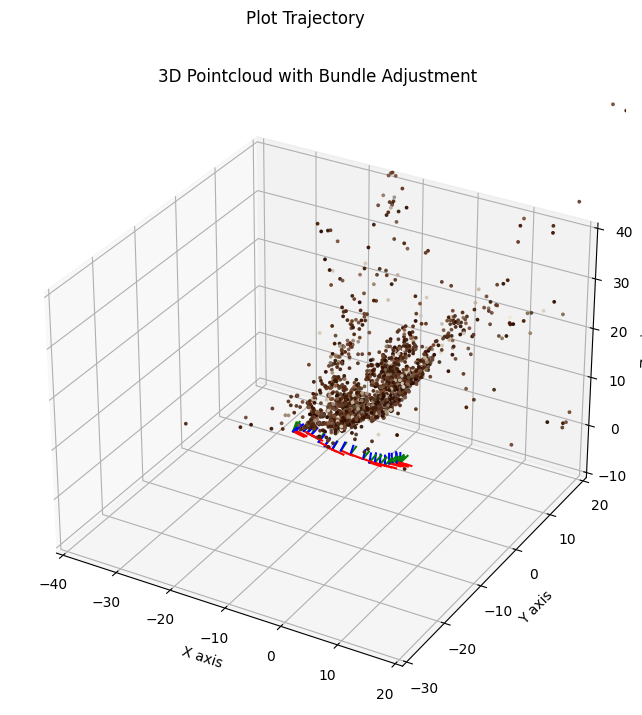

In [32]:
%matplotlib inline

plt.rcParams['figure.figsize'] = (20, 12)
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(projection='3d')

final_object_points = []
for index in range(len(all_object_points)):
    final_object_points.append(result.atPoint3(symbol_L(index)))

final_object_points = np.array(final_object_points)

ax.scatter(final_object_points[:, 0],
          final_object_points[:, 1], 
         final_object_points[:, 2], 
          c=all_object_points_color/255., 
                     s=3)

gtsam.utils.plot.plot_trajectory(1, result, scale=2)
gtsam.utils.plot.set_axes_equal(1)

ax.set_xlim3d(-40, 20)
ax.set_ylim3d(-30, 20)
ax.set_zlim3d(-10, 40)

plt.title("3D Pointcloud with Bundle Adjustment")

plt.show()

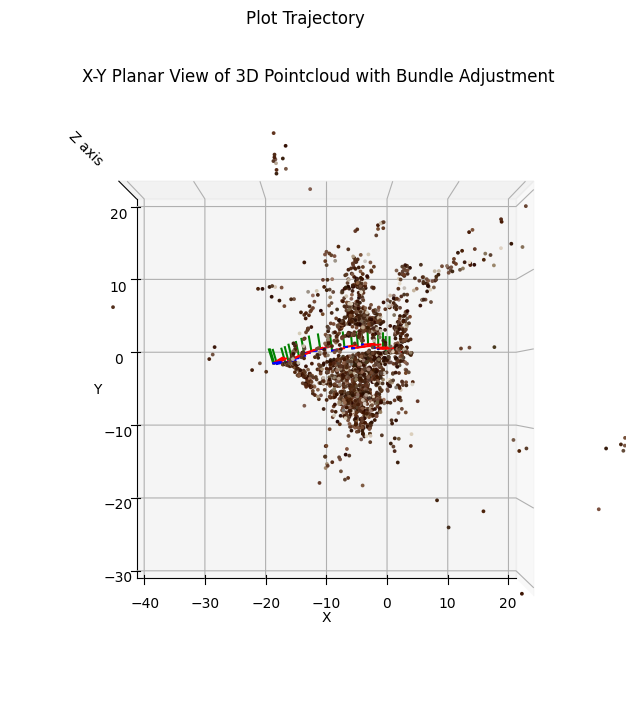

In [33]:
%matplotlib inline

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(projection='3d')

final_object_points = []
for index in range(len(all_object_points)):
    final_object_points.append(result.atPoint3(symbol_L(index)))

final_object_points = np.array(final_object_points)

ax.scatter(final_object_points[:, 0],
           final_object_points[:, 1], 
           final_object_points[:, 2], 
           c=all_object_points_color/255., 
           s=3)

gtsam.utils.plot.plot_trajectory(1, result, scale=2)
gtsam.utils.plot.set_axes_equal(1)

ax.set_xlim3d(-40, 20)
ax.set_ylim3d(-30, 20)
ax.set_zlim3d(-10, 40)

# Set the view to top-down
ax.view_init(elev=90, azim=-90)

# Hide the z-axis
ax.set_zticks([])

# Add labels
ax.set_xlabel('X')
ax.set_ylabel('Y')

plt.title("X-Y Planar View of 3D Pointcloud with Bundle Adjustment")

plt.show()
